# Análise do OpenRCA Telecom: dados, classes e baselines (E1–E4)

Este notebook reúne, num só lugar, o que as etapas E1 a E4 encontraram no subconjunto Telecom do OpenRCA:

1. a estrutura dos dados e as classes (motivos, componentes, tipos de consulta);
2. o achado dos **dias quase duplicados**, que levou à exclusão de três dias (ADR 0008);
3. a construção das janelas e dos rótulos por dobra (ADR 0007);
4. a medição de **sinal precursor**, que mudou a Tarefa A de predição para detecção precoce;
5. os **baselines** da E4 e a armadilha da revocação por evento (ADR 0010).

**Fontes.** Os números vêm dos artefatos gerados pelos comandos do projeto (`tcc-rca tasks`, `tcc-rca baselines`), em `reports/tables/`, e da matriz da E2 em `data/processed/` (não versionada). Nada é recalculado de forma diferente do pipeline; onde o notebook calcula algo novo (similaridade entre dias, exemplos de séries), isso é dito na célula.

**Licença.** A telemetria do OpenRCA é CC BY-NC 4.0: este notebook mostra só agregados e gráficos, nunca tabelas de valores brutos.

**Como rodar:** `uv run tcc-rca series && uv run tcc-rca tasks && uv run tcc-rca baselines --config configs/base.yaml configs/experiment/baselines.yaml` (e o mesmo com `baselines_sem_isencao.yaml`); depois abrir este notebook com o kernel do projeto (`uv run jupyter lab` ou o VS Code).

In [1]:
import json
import os
from collections import Counter
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display

from tcc_rca.config import load_config
from tcc_rca.dataset.build import failure_days
from tcc_rca.ingestion.cases import build_cases, read_failures, read_queries
from tcc_rca.ingestion.timeutil import utc_to_local_str

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # the project's configs use paths relative to the repository root

config = load_config("configs/base.yaml")
SYSTEM = config.target_system
TABLES = Path("reports/tables")
system_dir = config.paths.data_root / SYSTEM
values = pl.read_parquet(config.paths.processed_dir / SYSTEM / "series.parquet")
windows = pl.read_parquet(config.paths.processed_dir / SYSTEM / "windows.parquet")
tasks = json.loads((TABLES / f"tasks_{SYSTEM}.json").read_text(encoding="utf-8"))
base = json.loads((TABLES / f"baselines_{SYSTEM}_baselines.json").read_text(encoding="utf-8"))
control = json.loads(
    (TABLES / f"baselines_{SYSTEM}_baselines_sem_isencao.json").read_text(encoding="utf-8")
)
failures = read_failures(system_dir / "record.csv")
cases, _ = build_cases(read_queries(system_dir / "query.csv"), failures)
f_days = failure_days(failures, values.select("day", "time_utc"))
print(f"{values.height} minutos x {values.width - 2} atributos; {len(failures)} falhas")

5401 minutos x 2138 atributos; 51 falhas


### Estilo dos gráficos

Paleta categórica de referência, validada para daltonismo nos slots usados (no máximo 4 por gráfico); grade e eixos em linhas finas e discretas; uma cor por série, nunca por posição. Os tons verde-água e amarelo ficam abaixo de 3:1 de contraste com o fundo, por isso cada gráfico vem acompanhado de uma tabela com os números.

In [2]:
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow
MUTED, INK, INK2, GRID, AXIS = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "lines.linewidth": 2,
        "font.family": "sans-serif",
        "figure.dpi": 110,
    }
)


def hbar(ax, labels, counts, color=SLOTS[0]):
    # Thin horizontal bars, one series, value printed at the bar end.
    y = np.arange(len(labels))
    ax.barh(y, counts, height=0.6, color=color, edgecolor="#fcfcfb", linewidth=2)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    for yi, c in zip(y, counts, strict=True):
        ax.text(c, yi, f" {c}", va="center", fontsize=8, color=INK2)

## 1. Estrutura dos dados e classes

O Telecom tem **15 dias**, cada um cobrindo só **6 horas** (00:00–06:00 UTC+8), com amostras a cada 60 s. As 51 falhas rotuladas estão em 11 dias; quatro dias de abril não têm nenhum rótulo. A divisão temporal (E3) usa 2020_04_11 e 2020_04_20 como bloco inicial de treino/validação e testa cada dia de maio uma vez. Os três dias marcados como *excluído* são explicados na seção 2.

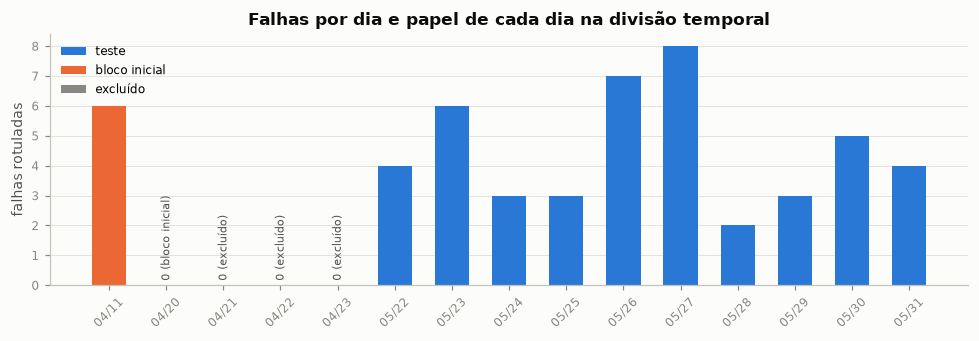

dia,falhas,papel
str,i64,str
"""2020_04_11""",6,"""bloco inicial"""
"""2020_04_20""",0,"""bloco inicial"""
"""2020_04_21""",0,"""excluído"""
"""2020_04_22""",0,"""excluído"""
"""2020_04_23""",0,"""excluído"""
…,…,…
"""2020_05_27""",8,"""teste"""
"""2020_05_28""",2,"""teste"""
"""2020_05_29""",3,"""teste"""


In [3]:
days = values["day"].unique().sort().to_list()
per_day = Counter(f_days)
excluded = set(config.tasks.excluded_days)
initial = set(tasks["initial_block_days"])
role = ["excluído" if d in excluded else "bloco inicial" if d in initial else "teste" for d in days]
day_table = pl.DataFrame({"dia": days, "falhas": [per_day.get(d, 0) for d in days], "papel": role})

fig, ax = plt.subplots(figsize=(9, 3.2))
colors = {"teste": SLOTS[0], "bloco inicial": SLOTS[1], "excluído": MUTED}
x = np.arange(len(days))
for r, color in colors.items():
    idx = [i for i, rr in enumerate(role) if rr == r]
    ax.bar(x[idx], day_table["falhas"].to_numpy()[idx], width=0.6, color=color, label=r)
for i, (d, r) in enumerate(zip(days, role, strict=True)):
    if per_day.get(d, 0) == 0:  # zero-height bar: print the role so the day stays legible
        ax.text(i, 0.15, f"0 ({r})", rotation=90, ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(x, [d[5:].replace("_", "/") for d in days], rotation=45)
ax.set_ylabel("falhas rotuladas")
ax.set_title("Falhas por dia e papel de cada dia na divisão temporal")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
display(day_table)

### Classes: motivos, componentes e tipos de consulta

O rótulo de cada falha tem três partes: **instante**, **componente** e **motivo**. As classes são desbalanceadas: `CPU fault` sozinho tem 19 das 51 falhas, e alguns componentes aparecem uma única vez. Os 7 tipos de consulta do OpenRCA pedem combinações diferentes desses três elementos (`task_1` só o instante, `task_7` os três).

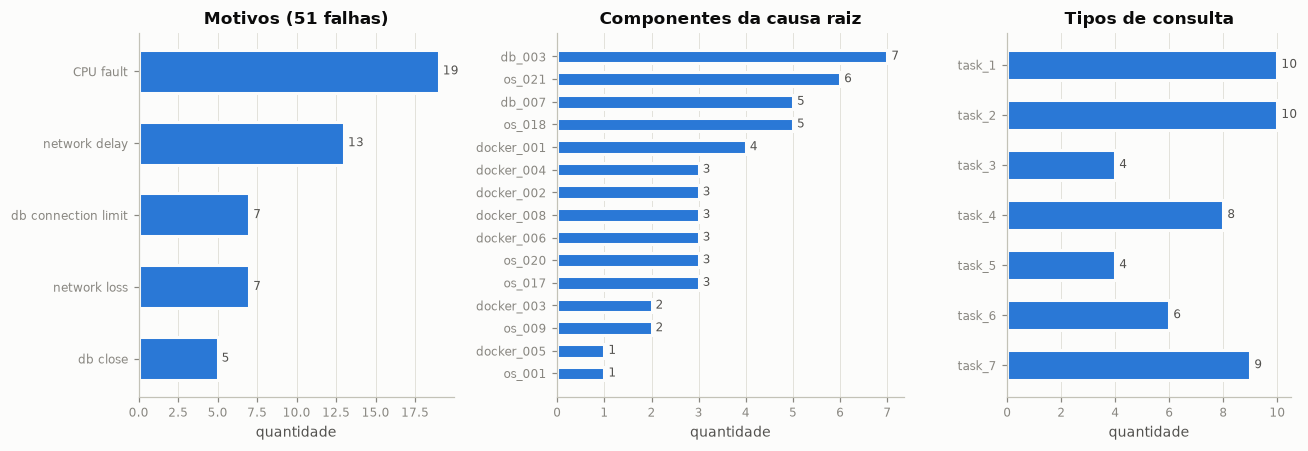

Falhas por tipo de componente: {'docker': 19, 'db': 12, 'os': 20}


motivo,os,db,docker
str,u32,u32,u32
"""CPU fault""",0,0,19
"""db close""",0,5,0
"""db connection limit""",0,7,0
"""network delay""",13,0,0
"""network loss""",7,0,0


In [4]:
reasons = Counter(f.reason for f in failures).most_common()
components = Counter(f.component for f in failures).most_common()
task_types = sorted(Counter(c.query.task_index for c in cases).items())

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.1, 0.9]})
hbar(axes[0], [r for r, _ in reasons], [n for _, n in reasons])
axes[0].set_title("Motivos (51 falhas)")
hbar(axes[1], [c for c, _ in components], [n for _, n in components])
axes[1].set_title("Componentes da causa raiz")
hbar(axes[2], [t for t, _ in task_types], [n for _, n in task_types])
axes[2].set_title("Tipos de consulta")
for ax in axes:
    ax.set_xlabel("quantidade")
plt.tight_layout()
plt.show()

kinds = Counter(f.component.split("_")[0] for f in failures)
reason_by_kind = (
    pl.DataFrame(
        {
            "motivo": [f.reason for f in failures],
            "tipo": [f.component.split("_")[0] for f in failures],
        }
    )
    .group_by("motivo", "tipo")
    .len()
    .pivot(on="tipo", index="motivo", values="len")
    .fill_null(0)
    .sort("motivo")
)
print("Falhas por tipo de componente:", dict(kinds))
display(reason_by_kind)

**Leitura.** No Telecom, cada motivo ocorre em **um único tipo** de componente: `CPU fault` só em contêineres (`docker_*`), `network delay` e `network loss` só em hosts (`os_*`), e `db close` e `db connection limit` só em bancos (`db_*`). O tipo do componente restringe o motivo a no máximo duas opções, algo que o agente da E7 pode explorar. Esse é um padrão deste conjunto de dados, não uma regra geral de sistemas de telecomunicações.

## 2. Achado: dias quase duplicados

A E1 notou que alguns pares de dias tinham exatamente o mesmo número de spans. A E3 mediu, célula a célula, a fração de valores de métricas iguais entre cada par de dias (alinhados pelo minuto do dia). Os traces ficam de fora porque só existem em parte dos dias. Esta célula refaz essa medida.

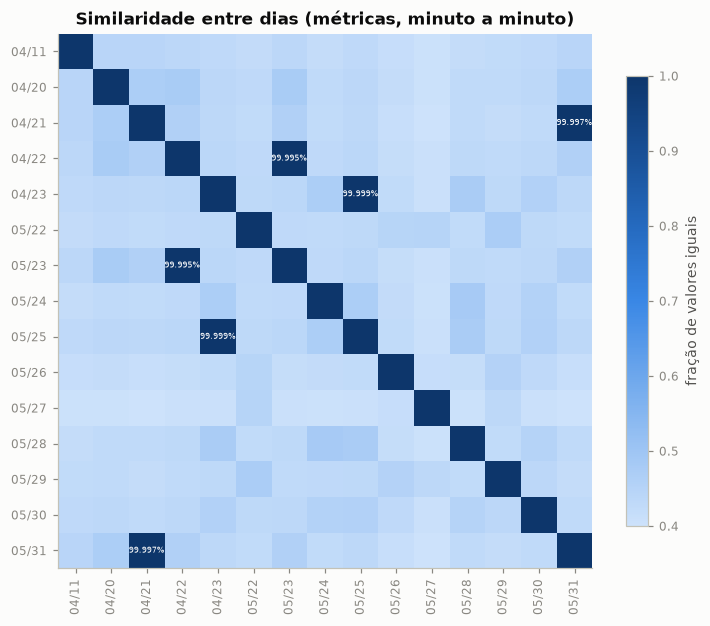

dia_a,dia_b,fracao_igual
str,str,f64
"""2020_04_21""","""2020_05_31""",0.99997
"""2020_04_22""","""2020_05_23""",0.99995
"""2020_04_23""","""2020_05_25""",0.99999


Demais pares: entre 0.40 e 0.48


In [5]:
metric_features = [c for c in values.columns if "::" in c and "trace_" not in c]
mats = {
    d: values.filter(pl.col("day") == d).select(metric_features).to_numpy()[:360].astype(float)
    for d in days
}
sim = np.eye(len(days))
for i, a in enumerate(days):
    for j in range(i + 1, len(days)):
        xa, xb = mats[a], mats[days[j]]
        both = ~np.isnan(xa) & ~np.isnan(xb)
        sim[i, j] = sim[j, i] = (np.isclose(xa, xb, rtol=1e-9) & both).sum() / both.sum()

fig, ax = plt.subplots(figsize=(6.8, 5.8))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", SEQ)
im = ax.imshow(sim, cmap=cmap, vmin=0.4, vmax=1.0)
labels = [d[5:].replace("_", "/") for d in days]
ax.set_xticks(range(len(days)), labels, rotation=90)
ax.set_yticks(range(len(days)), labels)
ax.grid(visible=False)
for i in range(len(days)):
    for j in range(len(days)):
        if i != j and sim[i, j] > 0.9:
            ax.text(
                j,
                i,
                f"{100 * sim[i, j]:.3f}%",
                ha="center",
                va="center",
                fontsize=5.5,
                color="#ffffff",
            )
fig.colorbar(im, ax=ax, shrink=0.8, label="fração de valores iguais")
ax.set_title("Similaridade entre dias (métricas, minuto a minuto)")
plt.tight_layout()
plt.show()

off = sim[~np.eye(len(days), dtype=bool)]
pairs = [
    (days[i], days[j], round(float(sim[i, j]), 5))
    for i in range(len(days))
    for j in range(i + 1, len(days))
    if sim[i, j] > 0.9
]
display(pl.DataFrame(pairs, schema=["dia_a", "dia_b", "fracao_igual"], orient="row"))
print(f"Demais pares: entre {np.sort(off)[0]:.2f} e {np.sort(off[off < 0.9])[-1]:.2f}")

**Leitura.** Três pares se destacam com mais de 99,99% de valores iguais: 04/21–05/31, 04/22–05/23 e 04/23–05/25. Todos os outros pares ficam entre 40% e 48%, e essa coincidência vem quase toda de séries constantes. O membro de abril de cada par **não tem falhas rotuladas**, enquanto o de maio tem 4, 6 e 3.

As poucas diferenças dentro de cada par caem logo depois dos inícios das falhas do gêmeo de maio: em 04/22 vs 05/23, logo após **todas as seis** falhas (gráfico abaixo). Isso indica que os dias de abril contêm as **mesmas falhas, sem rótulo**. Usá-los como dias "normais" vazaria a telemetria de teste para o treino e ensinaria ao modelo que falha é normal. Por isso foram excluídos (ADR 0008).

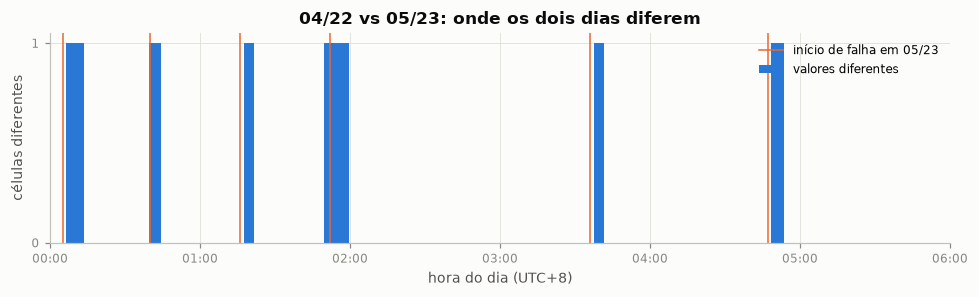

Inícios das falhas em 05/23 (min do dia): [5, 40, 76, 112, 216, 287]
Minutos com diferença: [7, 8, 9, 10, 11, 12, 13, 40, 41, 42, 43, 44, 78, 79, 80, 81, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 218, 219, 220, 221, 289, 290, 291, 292, 293]


In [6]:
pair = ("2020_04_22", "2020_05_23")
xa, xb = mats[pair[0]], mats[pair[1]]
both = ~np.isnan(xa) & ~np.isnan(xb)
diff_per_minute = (both & ~np.isclose(xa, xb, rtol=1e-9)).sum(axis=1)
onsets = [
    int(utc_to_local_str(f.start_utc)[11:13]) * 60 + int(utc_to_local_str(f.start_utc)[14:16])
    for f, d in zip(failures, f_days, strict=True)
    if d == pair[1]
]

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(np.arange(360), diff_per_minute, width=1.0, color=SLOTS[0], label="valores diferentes")
for k, o in enumerate(onsets):
    ax.axvline(o, color=SLOTS[1], linewidth=1, label="início de falha em 05/23" if k == 0 else None)
ax.set_xlim(0, 360)
ax.set_xticks(range(0, 361, 60), [f"{h:02d}:00" for h in range(7)])
ax.set_xlabel("hora do dia (UTC+8)")
ax.set_ylabel("células diferentes")
ax.set_yticks([0, 1])
ax.set_title("04/22 vs 05/23: onde os dois dias diferem")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
print("Inícios das falhas em 05/23 (min do dia):", onsets)
print("Minutos com diferença:", np.flatnonzero(diff_per_minute).tolist())

## 3. Janelas, rótulos e dobras (E3)

Cada exemplo da Tarefa A é uma **janela de 20 minutos** que termina no minuto *t* e nunca atravessa dias. Como o OpenRCA rotula só o **início** de cada falha, sem duração, há três classes de janela:

- **positiva (1):** um início de falha cai em [*t* − 5, *t*] min, isto é, a falha começou nos últimos 5 minutos;
- **normal (0):** a janela não toca [início − 5, início + 30] min de nenhuma falha;
- **ignorada:** perto demais de uma falha para ser normal, mas fora da faixa positiva. Não é usada como normal no treino nem como negativa na avaliação.

As 10 dobras de origem móvel testam um dia de maio cada; o treino cresce a cada dobra.

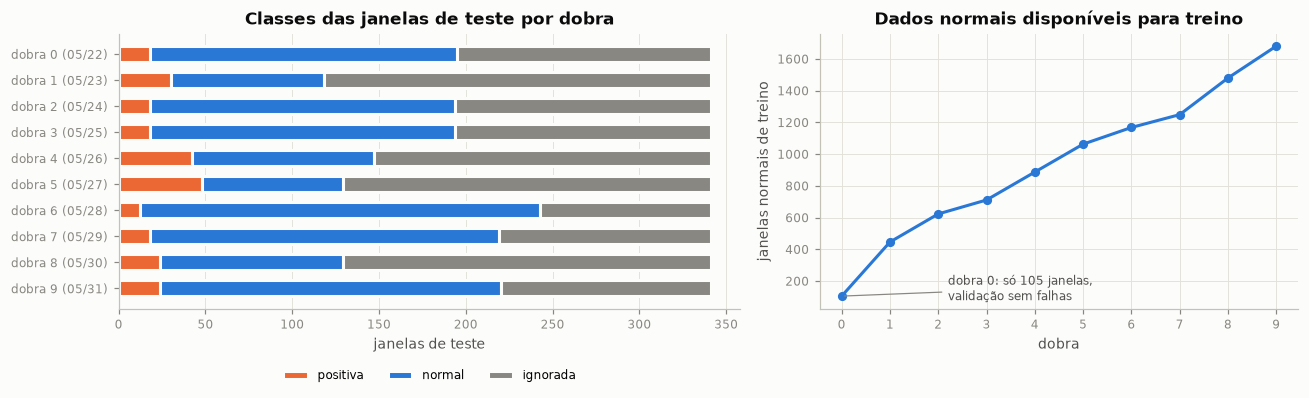

fold,test_day,train_normal_windows,test_positive_windows,test_negative_windows,test_ignored_windows,test_failures
i64,str,i64,i64,i64,i64,i64
0,"""2020_05_22""",105,18,177,146,4
1,"""2020_05_23""",446,30,88,223,6
2,"""2020_05_24""",623,18,176,147,3
3,"""2020_05_25""",711,18,176,147,3
4,"""2020_05_26""",887,42,105,194,7
5,"""2020_05_27""",1063,48,81,212,8
6,"""2020_05_28""",1168,12,231,98,2
7,"""2020_05_29""",1249,18,201,122,3
8,"""2020_05_30""",1480,24,105,212,5


Taxa de positivos nas janelas rotuladas: 0.125


In [7]:
folds = pl.DataFrame(tasks["fold_details"]).select(
    "fold",
    "test_day",
    "train_normal_windows",
    "test_positive_windows",
    "test_negative_windows",
    "test_ignored_windows",
    "test_failures",
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
y = np.arange(folds.height)
left = np.zeros(folds.height)
for col, name, color in (
    ("test_positive_windows", "positiva", SLOTS[1]),
    ("test_negative_windows", "normal", SLOTS[0]),
    ("test_ignored_windows", "ignorada", MUTED),
):
    vals = folds[col].to_numpy()
    ax.barh(
        y, vals, left=left, height=0.6, color=color, edgecolor="#fcfcfb", linewidth=2, label=name
    )
    left += vals
ax.set_yticks(
    y,
    [
        f"dobra {f} ({d[5:].replace('_', '/')})"
        for f, d in folds.select("fold", "test_day").iter_rows()
    ],
)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("janelas de teste")
ax.set_title("Classes das janelas de teste por dobra")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=3)

ax = axes[1]
ax.plot(folds["fold"], folds["train_normal_windows"], color=SLOTS[0], marker="o", markersize=5)
ax.set_xticks(folds["fold"].to_list())
ax.set_xlabel("dobra")
ax.set_ylabel("janelas normais de treino")
ax.set_title("Dados normais disponíveis para treino")
ax.annotate(
    "dobra 0: só 105 janelas,\nvalidação sem falhas",
    (0, 105),
    (2.2, 150),
    fontsize=8,
    color=INK2,
    va="center",
    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8},
)
plt.tight_layout()
plt.show()
display(folds)
labelled = windows.filter(pl.col("label").is_not_null())
print(f"Taxa de positivos nas janelas rotuladas: {labelled['label'].mean():.3f}")

## 4. Existe sinal precursor? (E3)

Antes de escolher entre **predição** (antecipar a falha) e **detecção** (perceber logo após o início), a E3 mediu, sem aprendizado, se os KPIs mudam antes do início. Cada minuto recebe uma pontuação de anomalia: a média das 10 maiores |z| robustas, com o escalonamento ajustado só no bloco inicial. Para cada antecedência *L*, a pontuação *L* minutos antes de cada uma das 45 falhas de teste é comparada com a dos minutos normais por AUROC. O valor 0,5 corresponde ao acaso.

A regra, fixada antes de olhar o resultado: existe precursor numa antecedência *L* > 0 se o IC de 95% ficar inteiro acima de 0,5.

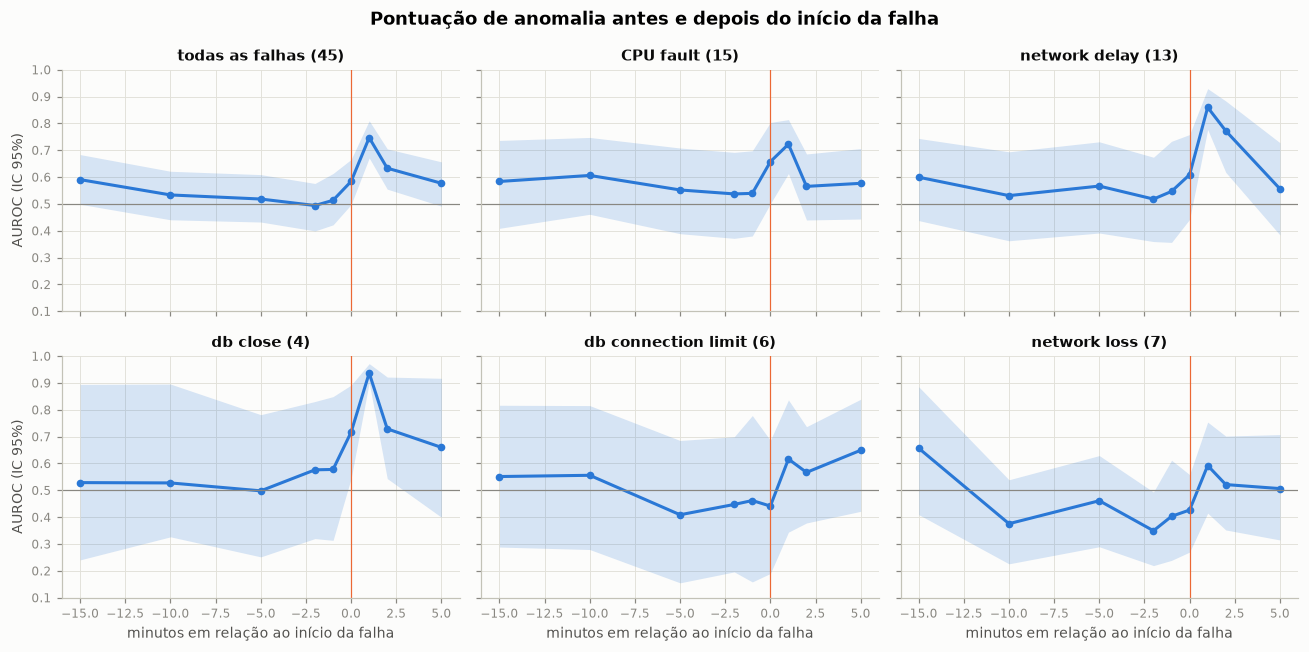

lead_minutes,group,n_pos,n_neg,auroc,ci_low,ci_high
i64,str,i64,i64,f64,f64,f64
15,"""all""",42,2093,0.5904,0.4986,0.6836
10,"""all""",43,2093,0.5333,0.4408,0.6215
5,"""all""",45,2093,0.5181,0.4324,0.609
2,"""all""",45,2093,0.4939,0.3993,0.576
1,"""all""",45,2093,0.5133,0.4219,0.6131
0,"""all""",45,2093,0.5838,0.4976,0.6655
-1,"""all""",45,2093,0.7467,0.6712,0.8097
-2,"""all""",45,2093,0.6329,0.5549,0.7049
-5,"""all""",45,2093,0.5768,0.4915,0.6565


In [8]:
prec = pl.read_csv(TABLES / f"precursor_{SYSTEM}.csv")
groups = ["all", "CPU fault", "network delay", "db close", "db connection limit", "network loss"]
titles = {"all": "todas as falhas (45)"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for ax, g in zip(axes.flat, groups, strict=True):
    d = prec.filter(pl.col("group") == g).sort("lead_minutes")
    lead = -d["lead_minutes"].to_numpy()  # plot time relative to the onset: negative = before
    ax.fill_between(lead, d["ci_low"], d["ci_high"], color=SLOTS[0], alpha=0.18, linewidth=0)
    ax.plot(lead, d["auroc"], color=SLOTS[0], marker="o", markersize=4)
    ax.axhline(0.5, color=MUTED, linewidth=0.8)
    ax.axvline(0, color=SLOTS[1], linewidth=0.8)
    n = d["n_pos"].max()
    ax.set_title(titles.get(g, f"{g} ({n})"), fontsize=10)
    ax.set_ylim(0.1, 1.0)
for ax in axes[1]:
    ax.set_xlabel("minutos em relação ao início da falha")
for ax in axes[:, 0]:
    ax.set_ylabel("AUROC (IC 95%)")
fig.suptitle("Pontuação de anomalia antes e depois do início da falha", fontweight="bold")
plt.tight_layout()
plt.show()
display(prec.filter(pl.col("group") == "all").sort("lead_minutes", descending=True))

**Leitura.**

- **Não há precursor:** à esquerda da linha laranja (antes do início), todos os ICs incluem 0,5. Por isso a Tarefa A foi formulada como **detecção precoce** (ADR 0007).
- O sinal aparece **1 a 2 minutos depois** do início rotulado (AUROC 0,75 em +1 min). Isso é coerente com amostras de 60 s, que só registram a falha no minuto seguinte.
- Por motivo, `db close`, `network delay` e `CPU fault` ficam visíveis. Já `db connection limit` e `network loss` **não se distinguem do normal** com essa pontuação simples: são os casos difíceis.

### Exemplos de séries ao redor de uma falha

Para ilustrar o que "visível" significa, a próxima célula mostra, para uma falha de cada motivo, o KPI do componente-gabarito que mais muda entre os 30 minutos antes e os 10 minutos depois do início. Esta célula **usa o gabarito para escolher o que mostrar**; é só ilustração, não faz parte de nenhum método.

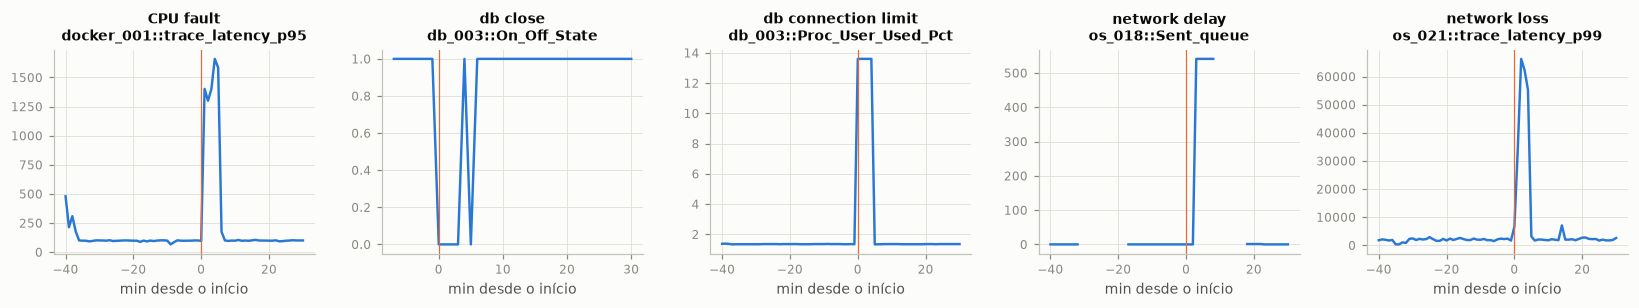

In [9]:
def most_changed_feature(component, onset):
    # KPI of `component` whose post-onset median departs most from the pre-onset spread.
    # Prefers well-covered series; relaxes the missing-data limit only if nothing qualifies.
    t = values["time_utc"]
    pre = values.filter((t >= onset - timedelta(minutes=30)) & (t < onset))
    post = values.filter((t >= onset) & (t < onset + timedelta(minutes=10)))
    for max_missing in (0.2, 0.5, 1.0):
        best, best_score = None, -1.0
        for f in (c for c in values.columns if c.startswith(component + "::")):
            a = pre[f].to_numpy().astype(float)
            b = post[f].to_numpy().astype(float)
            if np.isnan(a).mean() > max_missing or np.isnan(b).mean() > max_missing:
                continue
            a, b = a[~np.isnan(a)], b[~np.isnan(b)]
            if a.size == 0 or b.size == 0:
                continue
            # a constant pre-onset series gets a small relative spread instead of zero
            spread = np.std(a) or max(abs(np.median(a)), 1.0) * 1e-3
            score = abs(np.median(b) - np.median(a)) / spread
            if score > best_score:
                best, best_score = f, score
        if best is not None:
            return best
    raise ValueError(f"no KPI of {component} observed around {onset}")


tested = [(f, d) for f, d in zip(failures, f_days, strict=True) if d >= config.tasks.first_test_day]
examples = {}
for f, _ in tested:
    examples.setdefault(f.reason, f)
fig, axes = plt.subplots(1, len(examples), figsize=(15, 2.9))
for ax, (reason, f) in zip(axes, sorted(examples.items()), strict=True):
    feature = most_changed_feature(f.component, f.start_utc)
    t = values["time_utc"]
    win = values.filter(
        (t >= f.start_utc - timedelta(minutes=40)) & (t <= f.start_utc + timedelta(minutes=30))
    )
    minutes = ((win["time_utc"] - f.start_utc).dt.total_seconds() / 60).to_numpy()
    ax.plot(minutes, win[feature].to_numpy(), color=SLOTS[0], linewidth=1.6)
    ax.axvline(0, color=SLOTS[1], linewidth=0.8)
    ax.set_title(f"{reason}\n{feature}", fontsize=9)
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_xlabel("min desde o início")
plt.tight_layout()
plt.show()

## 5. Baselines da E4

Quatro detectores, todos ajustados por dobra só no treino, com limiar escolhido na validação, exceto o 3σ fixo:

- **z-score:** máximo de |z| entre KPIs e minutos da janela. `zscore_3sigma` usa limiar fixo em 3; `zscore_val` usa o limiar escolhido na validação.
- **Isolation Forest:** treinado nas janelas normais, sobre estatísticas de cada KPI na janela.
- **LightGBM:** supervisionado, treinado nas janelas rotuladas.

Todos os intervalos são IC de 95% por bootstrap, com as janelas reamostradas em blocos de 30 min.

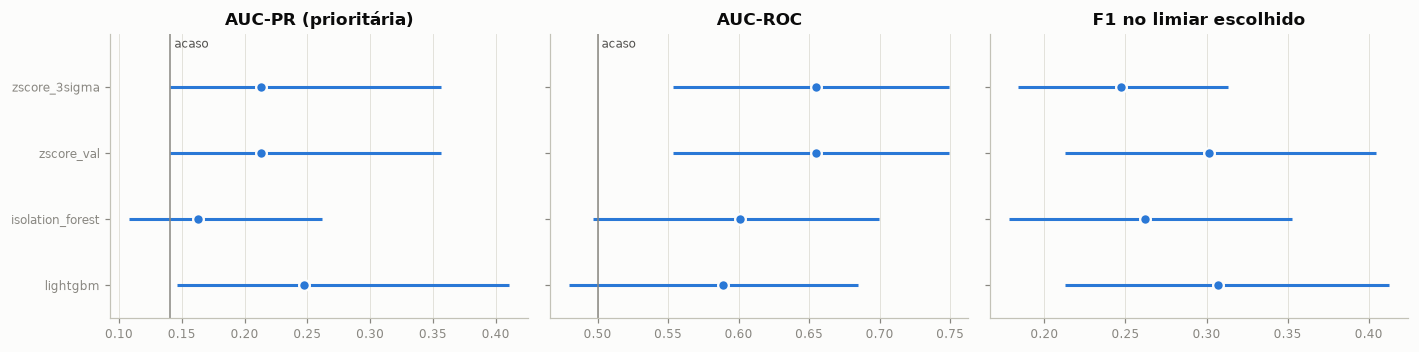

método,AUC-PR,AUC-ROC,F1,alarmes falsos/h
str,str,str,str,str
"""zscore_3sigma""","""0.21 [0.14, 0.36]""","""0.65 [0.55, 0.75]""","""0.25 [0.18, 0.31]""","""60.00 [60.00, 60.00]"""
"""zscore_val""","""0.21 [0.14, 0.36]""","""0.65 [0.55, 0.75]""","""0.30 [0.21, 0.40]""","""29.77 [23.20, 36.71]"""
"""isolation_forest""","""0.16 [0.11, 0.26]""","""0.60 [0.50, 0.70]""","""0.26 [0.18, 0.35]""","""30.35 [23.75, 37.16]"""
"""lightgbm""","""0.25 [0.15, 0.41]""","""0.59 [0.48, 0.68]""","""0.31 [0.21, 0.41]""","""17.50 [12.17, 23.17]"""


In [10]:
methods = list(base["detection"])
det = base["detection"]
pos_rate = det[methods[0]]["positive_rate"]


def dot_ci(ax, labels, estimates, color=SLOTS[0], ref=None, ref_label=None):
    y = np.arange(len(labels))
    v = np.array([e["value"] for e in estimates])
    lo = np.array([e["ci_low"] for e in estimates])
    hi = np.array([e["ci_high"] for e in estimates])
    ax.hlines(y, lo, hi, color=color, linewidth=2)
    ax.plot(v, y, "o", color=color, markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    if ref is not None:
        ax.axvline(ref, color=MUTED, linewidth=1)
        ax.text(ref, -0.55, f" {ref_label}", fontsize=8, color=INK2, va="bottom")
    # first label on top; explicit limits (not invert_yaxis) so shared y-axes stay consistent
    ax.set_ylim(len(labels) - 0.5, -0.8)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
dot_ci(axes[0], methods, [det[m]["auc_pr"] for m in methods], ref=pos_rate, ref_label="acaso")
axes[0].set_title("AUC-PR (prioritária)")
dot_ci(axes[1], methods, [det[m]["auc_roc"] for m in methods], ref=0.5, ref_label="acaso")
axes[1].set_title("AUC-ROC")
dot_ci(axes[2], methods, [det[m]["f1"] for m in methods])
axes[2].set_title("F1 no limiar escolhido")
plt.tight_layout()
plt.show()


def fmt(e):
    return f"{e['value']:.2f} [{e['ci_low']:.2f}, {e['ci_high']:.2f}]"


display(
    pl.DataFrame(
        {
            "método": methods,
            "AUC-PR": [fmt(det[m]["auc_pr"]) for m in methods],
            "AUC-ROC": [fmt(det[m]["auc_roc"]) for m in methods],
            "F1": [fmt(det[m]["f1"]) for m in methods],
            "alarmes falsos/h": [fmt(det[m]["false_alarms_per_hour"]) for m in methods],
        }
    )
)

**Leitura.** Todos os detectores ficam **pouco acima do acaso**. Na AUC-PR, o valor ao acaso é a taxa de positivos, 0,14, e só o IC do LightGBM começa acima dela. Esse é o piso que a LSTM (E5) precisa superar.

### A armadilha da revocação por evento

Uma falha conta como "detectada" se algum alarme cair em [início − 5, início + 30] min, um intervalo de 36 janelas. Com dezenas de alarmes falsos por hora, **alarmes aleatórios com a mesma taxa** também cairiam nesse intervalo. A revocação ao acaso é 1 − (1 − *p*)³⁶, onde *p* é a fração de janelas normais com alarme.

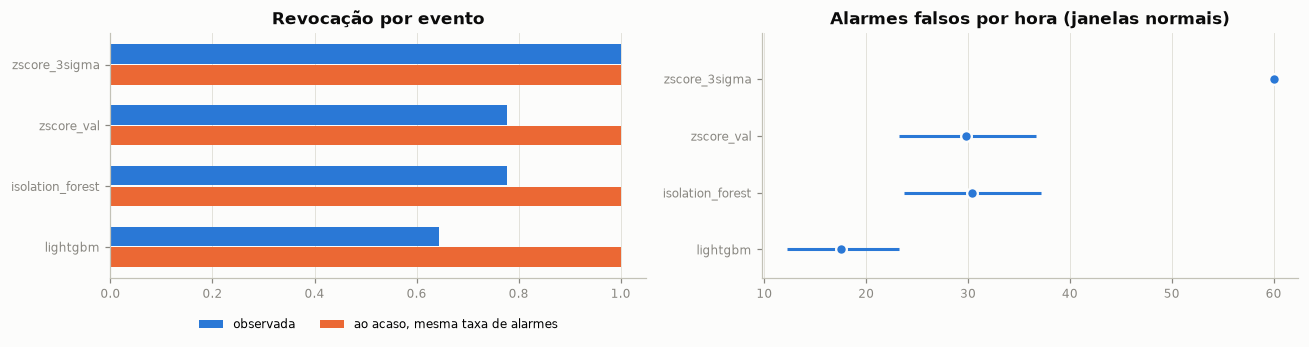

método,revocação por evento,ao acaso,falhas detectadas
str,f64,f64,i64
"""zscore_3sigma""",1.0,1.0,45
"""zscore_val""",0.7778,1.0,35
"""isolation_forest""",0.7778,1.0,35
"""lightgbm""",0.6444,1.0,29


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
y = np.arange(len(methods))
obs = [det[m]["event_recall"]["value"] for m in methods]
chance = [det[m]["event_recall_by_chance"] for m in methods]
axes[0].barh(y - 0.17, obs, height=0.32, color=SLOTS[0], label="observada")
axes[0].barh(y + 0.17, chance, height=0.32, color=SLOTS[1], label="ao acaso, mesma taxa de alarmes")
axes[0].set_yticks(y, methods)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.05)
axes[0].grid(axis="y", visible=False)
axes[0].set_title("Revocação por evento")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)
dot_ci(axes[1], methods, [det[m]["false_alarms_per_hour"] for m in methods])
axes[1].set_title("Alarmes falsos por hora (janelas normais)")
plt.tight_layout()
plt.show()
display(
    pl.DataFrame(
        {
            "método": methods,
            "revocação por evento": obs,
            "ao acaso": chance,
            "falhas detectadas": [det[m]["failures_detected"] for m in methods],
        }
    )
)

**Leitura.** A revocação ao acaso é **1,00 para todos os métodos**, então os 64–100% observados não medem detecção nenhuma. O mesmo vale para o atraso de detecção. Daqui em diante, revocação por evento só é reportada ao lado do seu nível de acaso, e o ganho real da LSTM terá de aparecer como **menos alarmes falsos com a mesma separação** (AUC-PR).

### Localização: heurística |z|

Para cada falha testada, os 56 componentes candidatos são ranqueados pelo maior |z| na janela que termina 5 minutos após o início. Empates contam contra o método (posto pessimista).

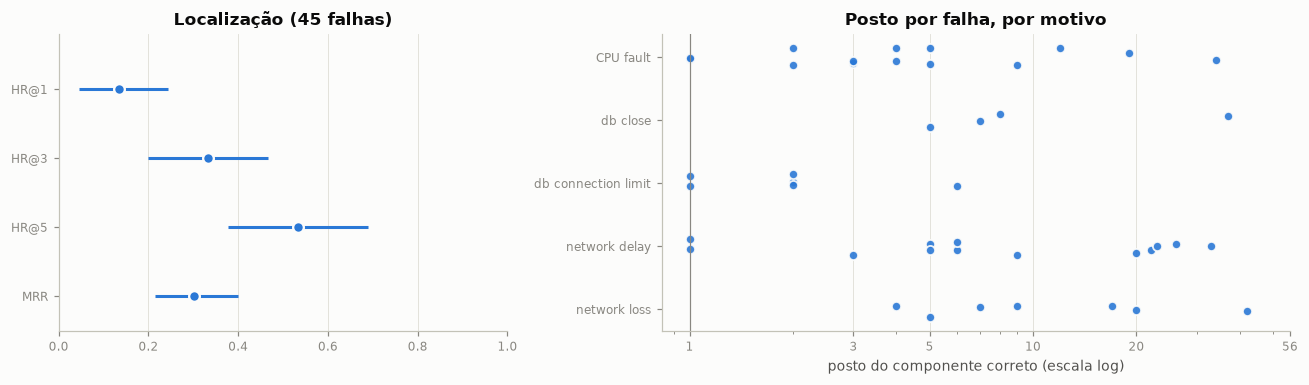

reason,falhas,HR@1,HR@5,posto mediano
str,u32,f64,f64,f64
"""CPU fault""",15,0.13,0.73,4.0
"""db close""",4,0.0,0.25,7.5
"""db connection limit""",6,0.33,0.83,2.0
"""network delay""",13,0.15,0.38,6.0
"""network loss""",7,0.0,0.29,9.0


In [12]:
runs = sorted(Path("experiments").glob("*-baselines"))
ranks = pl.read_csv(runs[-1] / "artifacts" / "localization_ranks.csv")
loc = base["localization"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
ks = ["hr@1", "hr@3", "hr@5", "mrr"]
dot_ci(axes[0], ["HR@1", "HR@3", "HR@5", "MRR"], [loc[k] for k in ks])
axes[0].set_xlim(0, 1)
axes[0].set_title("Localização (45 falhas)")

order = sorted(ranks["reason"].unique().to_list())
rng = np.random.default_rng(0)
for i, r in enumerate(order):
    rk = ranks.filter(pl.col("reason") == r)["rank"].to_numpy()
    axes[1].plot(
        rk,
        i + rng.uniform(-0.15, 0.15, rk.size),
        "o",
        color=SLOTS[0],
        markersize=6,
        markeredgecolor="#fcfcfb",
        markeredgewidth=1.2,
        alpha=0.9,
    )
axes[1].axvline(1, color=MUTED, linewidth=0.8)
axes[1].set_yticks(range(len(order)), order)
axes[1].invert_yaxis()
axes[1].set_xscale("log")
axes[1].set_xticks([1, 3, 5, 10, 20, 56], ["1", "3", "5", "10", "20", "56"])
axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("posto do componente correto (escala log)")
axes[1].set_title("Posto por falha, por motivo")
plt.tight_layout()
plt.show()
display(
    ranks.group_by("reason")
    .agg(
        pl.len().alias("falhas"),
        (pl.col("rank") == 1).mean().round(2).alias("HR@1"),
        (pl.col("rank") <= 5).mean().round(2).alias("HR@5"),
        pl.col("rank").median().alias("posto mediano"),
    )
    .sort("reason")
)

**Leitura.** A heurística acerta o componente na primeira posição em 13% das falhas e entre os 5 primeiros em 53%. `db close` nunca fica em primeiro, mesmo com o KPI `On_Off_State` mudando de 0 para 1. O motivo é a escala do z clássico: um KPI constante no treino recebe desvio de referência 1, então seu |z| vale no máximo 1, enquanto KPIs com desvio de treino minúsculo produzem |z| na casa dos milhares e vencem o máximo. É uma limitação que o XAI (E6) deve superar. Ela não foi corrigida no baseline, porque a correção teria sido escolhida olhando o teste.

### Diagnóstico completo: baseline constante (A0)

O baseline constante prevê sempre o componente e o motivo mais frequentes no treino, e o início da janela da consulta como instante, sem ler telemetria. A pontuação é feita pelo **script oficial do OpenRCA**.

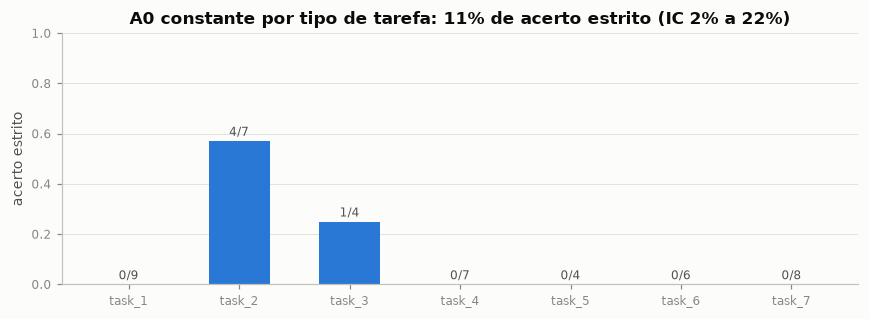

tarefa,n,strict_correct,partial_mean,acerto_estrito
str,i64,i64,f64,f64
"""task_1""",9,0,0.0,0.0
"""task_2""",7,4,0.5714,0.571429
"""task_3""",4,1,0.25,0.25
"""task_4""",7,0,0.0714,0.0
"""task_5""",4,0,0.0,0.0
"""task_6""",6,0,0.25,0.0
"""task_7""",8,0,0.165,0.0


In [13]:
con = base["diagnosis_constant"]
by_task = pl.DataFrame([{"tarefa": k, **v} for k, v in con["by_task"].items()]).with_columns(
    (pl.col("strict_correct") / pl.col("n")).alias("acerto_estrito")
)
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(by_task.height)
ax.bar(x, by_task["acerto_estrito"], width=0.55, color=SLOTS[0])
ax.set_xticks(x, by_task["tarefa"])
ax.set_ylim(0, 1)
ax.set_ylabel("acerto estrito")
ax.grid(axis="x", visible=False)
for xi, (c, n) in enumerate(by_task.select("strict_correct", "n").iter_rows()):
    ax.text(
        xi, by_task["acerto_estrito"][xi] + 0.02, f"{c}/{n}", ha="center", fontsize=8, color=INK2
    )
acc = con["strict_accuracy"]
ax.set_title(
    f"A0 constante por tipo de tarefa: {100 * acc['value']:.0f}% de acerto estrito "
    f"(IC {100 * acc['ci_low']:.0f}% a {100 * acc['ci_high']:.0f}%)"
)
plt.tight_layout()
plt.show()
display(by_task)

**Leitura.** São 11% de acerto estrito (5 de 45), todos em tarefas que pedem um único elemento: 4 em `task_2` (motivo, onde `CPU fault` é o mais frequente) e 1 em `task_3` (componente). Esse é o piso do agente na E7. Como referência externa, o issue #23 do OpenRCA relata 7,46% para um baseline constante no benchmark completo, que tem outro protocolo e não é comparável diretamente.

## 6. Sensibilidade à isenção dos KPIs de disponibilidade (ADR 0005)

Os KPIs de disponibilidade (`ICMP_ping`, `On_Off_State`…) são constantes no treino e seriam descartados pela seleção; a isenção que os mantém foi decidida depois de olhar os rótulos (ameaça à validade nº 1). Por isso todo resultado principal é reportado também **sem** a isenção.

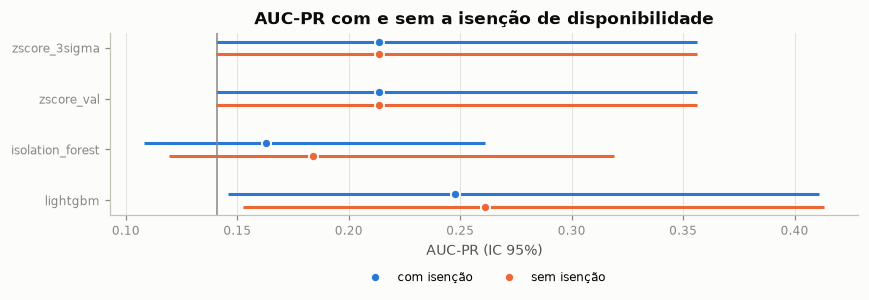

métrica,com isenção,sem isenção
str,str,str
"""AUC-PR zscore_3sigma""","""0.21 [0.14, 0.36]""","""0.21 [0.14, 0.36]"""
"""AUC-PR zscore_val""","""0.21 [0.14, 0.36]""","""0.21 [0.14, 0.36]"""
"""AUC-PR isolation_forest""","""0.16 [0.11, 0.26]""","""0.18 [0.12, 0.32]"""
"""AUC-PR lightgbm""","""0.25 [0.15, 0.41]""","""0.26 [0.15, 0.41]"""
"""HR@1 |z|""","""0.13 [0.04, 0.24]""","""0.13 [0.04, 0.24]"""
"""acerto estrito A0""","""0.11 [0.02, 0.22]""","""0.11 [0.02, 0.22]"""


In [14]:
fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(methods))
for k, (name, run, color) in enumerate(
    (("com isenção", base, SLOTS[0]), ("sem isenção", control, SLOTS[1]))
):
    e = [run["detection"][m]["auc_pr"] for m in methods]
    yy = y + (k - 0.5) * 0.25
    ax.hlines(yy, [x["ci_low"] for x in e], [x["ci_high"] for x in e], color=color, linewidth=2)
    ax.plot(
        [x["value"] for x in e],
        yy,
        "o",
        color=color,
        markersize=6,
        label=name,
        markeredgecolor="#fcfcfb",
        markeredgewidth=1.2,
    )
ax.axvline(pos_rate, color=MUTED, linewidth=1)
ax.set_yticks(y, methods)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC-PR (IC 95%)")
ax.set_title("AUC-PR com e sem a isenção de disponibilidade")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncols=2)
plt.tight_layout()
plt.show()
display(
    pl.DataFrame(
        {
            "métrica": [f"AUC-PR {m}" for m in methods] + ["HR@1 |z|", "acerto estrito A0"],
            "com isenção": [fmt(base["detection"][m]["auc_pr"]) for m in methods]
            + [
                fmt(base["localization"]["hr@1"]),
                fmt(base["diagnosis_constant"]["strict_accuracy"]),
            ],
            "sem isenção": [fmt(control["detection"][m]["auc_pr"]) for m in methods]
            + [
                fmt(control["localization"]["hr@1"]),
                fmt(control["diagnosis_constant"]["strict_accuracy"]),
            ],
        }
    )
)

**Leitura.** Nenhuma conclusão muda. O z-score e a localização ficam idênticos, porque os KPIs de disponibilidade nunca vencem o máximo de |z|. Nos modelos aprendidos, as diferenças ficam dentro dos ICs.

## 7. Síntese

| Achado | Consequência |
|---|---|
| Três dias de abril são cópias sem rótulo de dias de maio com falhas | Excluídos de tudo (ADR 0008); sem isso haveria vazamento |
| O dia mais antigo (04/11) não pode ser testado em ordem cronológica | 45 falhas testadas, não 51 |
| Não há sinal precursor; o sinal surge 1–2 min após o início | Tarefa A = detecção precoce (ADR 0007) |
| `db connection limit` e `network loss` são invisíveis à pontuação simples | São o alvo de melhoria da LSTM e do XAI |
| Cada motivo ocorre num único tipo de componente | O tipo do componente restringe o motivo (útil ao agente, E7) |
| Baselines de detecção pouco acima do acaso (melhor AUC-PR 0,25 vs 0,14) | Piso modesto, mas ICs largos: só ganhos grandes serão significativos |
| Revocação por evento dos baselines está no nível do acaso | Reportar sempre ao lado do acaso; o ganho real deve vir com menos alarmes falsos |
| z clássico subestima KPIs de estado (`On_Off_State`) | Explica HR@1 = 0 em `db close`; o XAI deve lidar com escalas |
| Isenção de disponibilidade não muda conclusões na E4 | A ameaça à validade correspondente segue sob controle |